# Analysis Notebook
Interactive analysis: EDA, plots, correlations, and OLS regression using the cleaned dataset.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

df = pd.read_csv('../data/cleaned_dataset.csv')
df.head()

,participant_id,gender,age,time_spent_hours,score,score_pct
0,fa90e901968a,Male,17,43.0,8,0.4
1,d104d30a026f,Female,30,20.0,10,0.5
2,39179df95d43,Male,17,20.0,8,0.4
3,ae72cb907ad9,Male,16,50.0,14,0.7
4,319488e8cd72,Male,25,42.0,12,0.6


In [2]:
# Descriptive statistics
display(df.describe(include='all'))

# Grouped by gender
display(df.groupby('gender')[['score_pct','time_spent_hours','age']].agg(['count','mean','std']))

,participant_id,gender,age,time_spent_hours,score,score_pct
count,102,102,102.000000,102.000000,102.000000,102.000000
unique,100,2,NaN,NaN,NaN,NaN
top,e705ffe85dde,Male,NaN,NaN,NaN,NaN
freq,2,58,NaN,NaN,NaN,NaN
mean,NaN,NaN,23.892157,25.124183,11.676471,0.583824
std,NaN,NaN,12.197960,18.337289,2.568514,0.128426
min,NaN,NaN,6.000000,0.166667,6.000000,0.300000
25%,NaN,NaN,18.000000,14.000000,10.000000,0.500000
50%,NaN,NaN,21.000000,21.000000,12.000000,0.600000
75%,NaN,NaN,23.750000,31.875000,13.000000,0.650000


score_pct                     time_spent_hours                        \
           count      mean       std            count       mean        std   
gender                                                                        
Female        44  0.554545  0.113516               44  21.170455  13.260337   
Male          58  0.606034  0.135426               58  28.123563  21.022673   

         age                        
       count       mean        std  
gender                              
Female    44  25.227273  15.167075  
Male      58  22.879310   9.364130

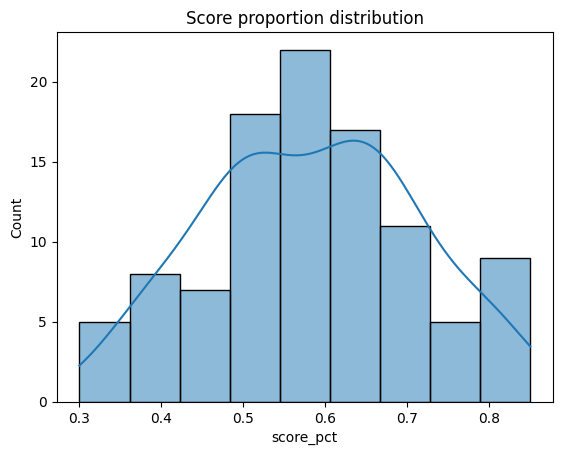

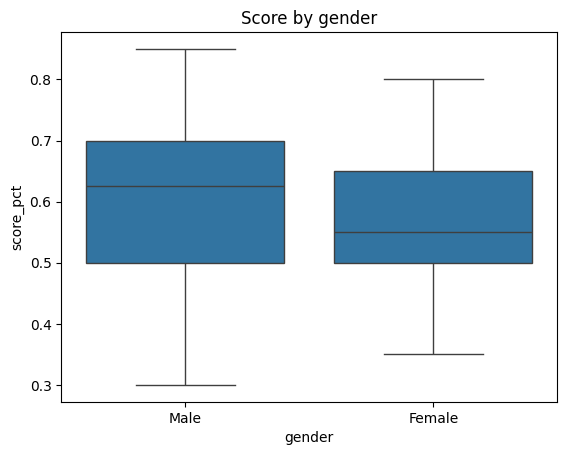

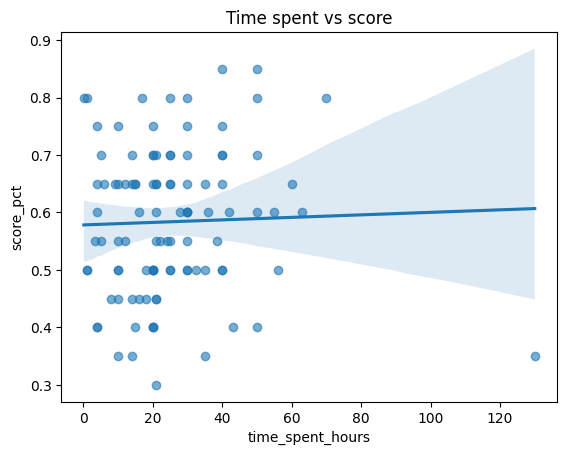

In [3]:
# Plots
sns.histplot(df['score_pct'].dropna(), kde=True)
plt.title('Score proportion distribution')
plt.show()

sns.boxplot(x='gender', y='score_pct', data=df)
plt.title('Score by gender')
plt.show()

sns.regplot(x='time_spent_hours', y='score_pct', data=df, scatter_kws={'alpha':0.6})
plt.title('Time spent vs score')
plt.show()

In [4]:
# Correlation and OLS regression
sub = df.dropna(subset=['time_spent_hours','score_pct'])
print('Pearson:', stats.pearsonr(sub['time_spent_hours'], sub['score_pct']))
print('Spearman:', stats.spearmanr(sub['time_spent_hours'], sub['score_pct']))

df_reg = df.dropna(subset=['score_pct','time_spent_hours'])
model = smf.ols('score_pct ~ time_spent_hours + C(gender) + age', data=df_reg).fit(cov_type='HC3')
print(model.summary())

Pearson: PearsonRResult(statistic=np.float64(0.031272422597865605), pvalue=np.float64(0.7550254935677432))
Spearman: SignificanceResult(statistic=np.float64(0.11335991112596408), pvalue=np.float64(0.25661421835981263))
                            OLS Regression Results                            
Dep. Variable:              score_pct   R-squared:                       0.064
Model:                            OLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                     2.057
Date:                Thu, 11 Dec 2025   Prob (F-statistic):              0.111
Time:                        01:39:16   Log-Likelihood:                 68.509
No. Observations:                 102   AIC:                            -129.0
Df Residuals:                      98   BIC:                            -118.5
Df Model:                           3                                         
Covariance Type:                  HC3                                 